# **Powering Palo Alto: Data-Driven Insights for EV Charging Operations**

**42577 Introduction to Business Analytics** DTU  Group 17

| Name | Student number |
|---|---|
| Georgia Panagopoulou | s263152 |
| Gonçalo Figueira | s263184 |
| Gyorkem Yozgyur | s263126 |
| Teresa Simão | s263065 |

-----------------------------------------

## **1. Data Pre-Processing**

-----------------------------------------

### Table of Contents

* [1.1 Importing the Datasets and Libraries](#1.1)
* [1.2 Preliminary Data Analysis and Arrangements](#1.2)
* [1.3 Exploring Data Distributions](#1.3)
* [1.4 Treating Inconsistencies](#1.4)
* [1.5 Feature Engineering](#1.5)
* [1.6 Data Visualization](#1.6)
* [1.7 Exporting the Datasets](#1.7)

-----------------------------------------

<a id="1.1"></a>
    
## <font color='#FFFFF'>1.1. Importing the datasets and libraries <font>

Libraries for data handling (pandas, numpy) and plotting (matplotlib, seaborn).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # if we want to use 
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

Raw data: one row per charging session.

In [ ]:
df = pd.read_csv("Data/EVChargingStationUsage.csv", low_memory=False)

Size and first rows.

In [3]:
print(df.shape)
df.head()

(259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Type,Port Number,Plug Type,EVSE ID,Address 1,City,State/Province,Postal Code,Country,Latitude,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,6.249457,2.625,0.784,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,0.106588,0.045,0.013,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,14.951777,6.280,1.876,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,7.159643,3.007,0.899,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,1.957765,0.822,0.246,Level 2,2,J1772,NaN,250 Hamilton Ave,Palo Alto,California,94301,United States,37.444572,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


-----------------------------------------

<a id="1.2"></a>
    
## <font color='#FFFFF'>1.2. Preliminary Data Analysis and Arrangements <font>

Structure, missing values and coverage, and a usable shape. No rows are removed here.

Column types and memory use.

In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

Missing values per column.

In [5]:
missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})
missing[missing["Missing"] > 0].sort_values("Missing", ascending=False)

,Missing,Missing (%)
County,84665,32.64
EVSE ID,78948,30.43
System S/N,78948,30.43
Model Number,78948,30.43
Driver Postal Code,8402,3.24
User ID,7677,2.96
Currency,1788,0.69
Ended By,248,0.10
Transaction Date (Pacific Time),209,0.08
Port Type,9,0.00


Duplicates, users, stations, time span and time zones.

In [ ]:
print("Duplicated rows:", df.duplicated().sum())
print("Unique User IDs:", df["User ID"].nunique())
print("Unique Station Names:", df["Station Name"].nunique())
print("Unique Port Numbers:", df["Port Number"].nunique())

start_dates = pd.to_datetime(df["Start Date"], errors="coerce") # we use this because here the start date is in string
print("First Start Date:", start_dates.min())
print("Last Start Date:", start_dates.max())

print()
print(df["Start Time Zone"].value_counts())
print()
print(df["End Time Zone"].value_counts())

Duplicated rows: 4
Unique User IDs: 21441
Unique Station Names: 47
Unique Port Numbers: 2
First Start Date: 2011-07-29 20:17:00
Last Start Date: 2020-12-31 18:19:00

Start Time Zone
PDT    166763
PST     92621
UTC        31
Name: count, dtype: int64

End Time Zone
PDT    166791
PST     92623
UTC         1
Name: count, dtype: int64


Numeric summary.

In [ ]:
df.describe() # here we show only the columns that are numeric

,Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Number,EVSE ID,Postal Code,Latitude,Longitude,Fee,Plug In Event Id,Driver Postal Code,System S/N
count,259415.000000,259415.000000,259415.000000,259415.000000,1.804670e+05,259415.000000,259415.000000,259415.000000,259415.000000,2.594150e+05,251013.000000,1.804670e+05
mean,8.544277,3.588596,1.072306,1.591627,1.462973e+05,94302.315768,37.439565,-122.151264,1.097481,1.188685e+08,94170.308255,1.443790e+11
std,7.185462,3.017894,0.901776,0.491534,2.429677e+05,1.941657,0.009621,0.015382,1.934408,4.057750e+08,4249.837126,2.483280e+10
min,0.010000,0.004000,0.001000,1.000000,3.792000e+03,94301.000000,37.422104,-122.163239,0.000000,1.000000e+00,1013.000000,1.023100e+11
25%,3.784000,1.589000,0.475000,1.000000,4.358300e+04,94301.000000,37.428318,-122.162170,0.000000,1.573000e+03,94087.000000,1.231100e+11
50%,6.868634,2.885000,0.862000,2.000000,1.074270e+05,94301.000000,37.444489,-122.158272,0.000000,3.573000e+03,94304.000000,1.427410e+11
75%,11.458340,4.813000,1.438000,2.000000,1.745590e+05,94303.000000,37.446613,-122.145699,1.640000,6.340000e+03,94804.000000,1.705410e+11
max,97.360000,40.891000,12.219000,2.000000,5.535441e+06,94306.000000,37.449375,-122.112480,84.560000,1.609436e+09,99354.000000,2.002410e+11


Dropped: four constant columns, three hardware identifiers missing until mid-2016, and County (~33% missing, inconsistent). Currency stays until 1.4.

In [ ]:
# Constants: Country, State/Province, City, Org Name so they are not useful for analysis
# Hardware identifiers missing for every session before Aug 2016: EVSE ID, System S/N, Model Number ad the station is already indentified by the port number
# County: ~33% MISSING OR INCONSISTENT WE NEED TO CHECK BECAUSE  PALO ALTO IS FROM SANTA CLARA NOT SAN MATEO
cols_to_drop = ["EVSE ID", "County", "System S/N", "Model Number",
                "Org Name", "Country", "State/Province", "City"]
df = df.drop(columns=cols_to_drop)
print(df.shape)
# from 33 columns to 25

(259415, 25)


Levels of the categorical columns; Port Type and Plug Type map one-to-one.

In [ ]:
for col in ["Port Type", "Plug Type", "Ended By"]:
    print(df[col].value_counts(dropna=False))
    print()

# Level 2 USES J1772 and Level 1 USES NEMA 5-20R, so missing port types can be filled in 1.4
print(pd.crosstab(df["Port Type"], df["Plug Type"]))

Port Type
Level 2    254727
Level 1      4679
NaN             9
Name: count, dtype: int64

Plug Type
J1772         254734
NEMA 5-20R      4681
Name: count, dtype: int64

Ended By
Plug Out at Vehicle             210721
Customer                         41090
CPS Server                        7065
NaN                                248
Outlet Unreachable                  64
Door Open                           57
Plug Removed While Rebooting        50
Unknown                             32
Final GFCI Tripped                  28
Door                                24
Final 4-strikes GFCI trip           15
Plug Out at Station                  7
Holster Plugin                       7
Station Offline                      3
OCD                                  2
Door Closed                          1
Relay Stuck Closed                   1
Name: count, dtype: int64

Plug Type   J1772  NEMA 5-20R
Port Type                    
Level 1         0        4679
Level 2    254727           0


Short snake_case column names.

In [ ]:
# just to make the names easier
df = df.rename(columns={
    "Station Name": "station", "MAC Address": "mac_address",
    "Start Date": "start", "Start Time Zone": "start_tz",
    "End Date": "end", "End Time Zone": "end_tz",
    "Transaction Date (Pacific Time)": "transaction_date",
    "Total Duration (hh:mm:ss)": "total_duration", "Charging Time (hh:mm:ss)": "charging_time",
    "Energy (kWh)": "energy_kwh", "GHG Savings (kg)": "ghg_kg", "Gasoline Savings (gallons)": "gasoline_gal",
    "Port Type": "port_type", "Port Number": "port_number", "Plug Type": "plug_type",
    "Address 1": "address", "Postal Code": "postal_code",
    "Latitude": "lat", "Longitude": "lon", "Fee": "fee", "Currency": "currency", "Ended By": "ended_by",
    "Plug In Event Id": "event_id", "Driver Postal Code": "driver_postal_code", "User ID": "user_id"
})
df.columns

Index(['station', 'mac_address', 'start', 'start_tz', 'end', 'end_tz',
       'transaction_date', 'total_duration', 'charging_time', 'energy_kwh',
       'ghg_kg', 'gasoline_gal', 'port_type', 'port_number', 'plug_type',
       'address', 'postal_code', 'lat', 'lon', 'currency', 'fee', 'ended_by',
       'event_id', 'driver_postal_code', 'user_id'],
      dtype='str')

Dates to datetime, durations to hours, repeated text to categories, and IDs and postal codes to text (they are codes, not quantities).

In [11]:
# errors="coerce" turns unparseable values into NaT: 40 end dates are stored as
# Excel serial numbers (e.g. 42845.81041); end is recomputed from the duration in 1.4
for col in ["start", "end", "transaction_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

for col in ["total_duration", "charging_time"]:
    df[col] = pd.to_timedelta(df[col], errors="coerce")

df["total_hours"] = df["total_duration"].dt.total_seconds() / 3600
df["charging_hours"] = df["charging_time"].dt.total_seconds() / 3600

for col in ["station", "port_type", "plug_type", "ended_by"]:
    df[col] = df[col].astype("category")

df["driver_postal_code"] = df["driver_postal_code"].astype("Int64").astype("string")
for col in ["postal_code", "event_id"]:
    df[col] = df[col].astype("string")

print(df[["start", "end", "transaction_date", "total_duration", "charging_time"]].isna().sum())
df.dtypes

start                 0
end                  40
transaction_date    249
total_duration        0
charging_time         0
dtype: int64


station                      category
mac_address                       str
start                  datetime64[us]
start_tz                          str
end                    datetime64[us]
end_tz                            str
transaction_date       datetime64[us]
total_duration        timedelta64[us]
charging_time         timedelta64[us]
energy_kwh                    float64
ghg_kg                        float64
gasoline_gal                  float64
port_type                    category
port_number                     int64
plug_type                    category
address                           str
postal_code                    string
lat                           float64
lon                           float64
currency                          str
fee                           float64
ended_by                     category
event_id                       string
driver_postal_code             string
user_id                           str
total_hours                   float64
charging_hou

Sessions per year.

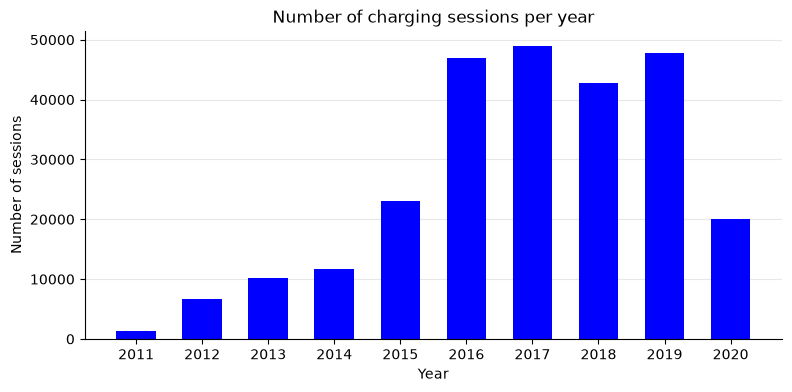

In [12]:
sessions_per_year = df["start"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(sessions_per_year.index, sessions_per_year.values, color="blue", width=0.6)
ax.set_title("Number of charging sessions per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of sessions")
ax.set_xticks(sessions_per_year.index)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Sessions and first/last session per station.

In [13]:
station_activity = (df.groupby("station", observed=True)["start"]
                    .agg(sessions="count", first_session="min", last_session="max")
                    .sort_values("sessions", ascending=False))
station_activity

,sessions,first_session,last_session
station,,,
PALO ALTO CA / HAMILTON #2,23721,2011-08-02 12:26:00,2020-11-04 04:54:00
PALO ALTO CA / HAMILTON #1,14888,2011-07-29 20:17:00,2020-11-03 18:03:00
PALO ALTO CA / WEBSTER #1,14432,2015-07-29 13:59:00,2020-12-31 17:49:00
PALO ALTO CA / BRYANT #2,14389,2011-10-10 15:23:00,2020-07-01 13:26:00
PALO ALTO CA / HIGH #4,13898,2011-09-02 20:42:00,2020-12-06 16:36:00
PALO ALTO CA / BRYANT #1,13436,2011-10-13 12:49:00,2020-08-30 13:22:00
PALO ALTO CA / WEBSTER #2,12669,2015-07-29 16:53:00,2020-12-30 17:57:00
PALO ALTO CA / CAMBRIDGE #1,11163,2016-01-14 11:19:00,2020-12-31 06:50:00
PALO ALTO CA / HIGH #1,10756,2015-07-29 15:51:00,2020-12-31 09:37:00


**Key findings.** 259,415 sessions, 21,441 users and 47 station names. Issues for 1.4: duplicates, UTC timestamps, Excel-format end dates and non-USD fees.

-----------------------------------------

<a id="1.3"></a>
    
## <font color='#FFFFF'>1.3. Exploring Data Distributions <font>

Distributions used to set the rules of 1.4. No rows are removed.

Idle time (plugged in but not charging) measures hoarding.

In [14]:
df["idle_hours"] = df["total_hours"] - df["charging_hours"]
df[["total_hours", "charging_hours", "idle_hours"]].head()

,total_hours,charging_hours,idle_hours
0,3.058889,1.900833,1.158056
1,0.035000,0.031667,0.003333
2,4.292222,4.291111,0.001111
3,2.056667,2.049444,0.007222
4,1.190000,0.731667,0.458333


Histograms clipped at the 99th percentile; idle time is cut at 0 and shown on a log scale.

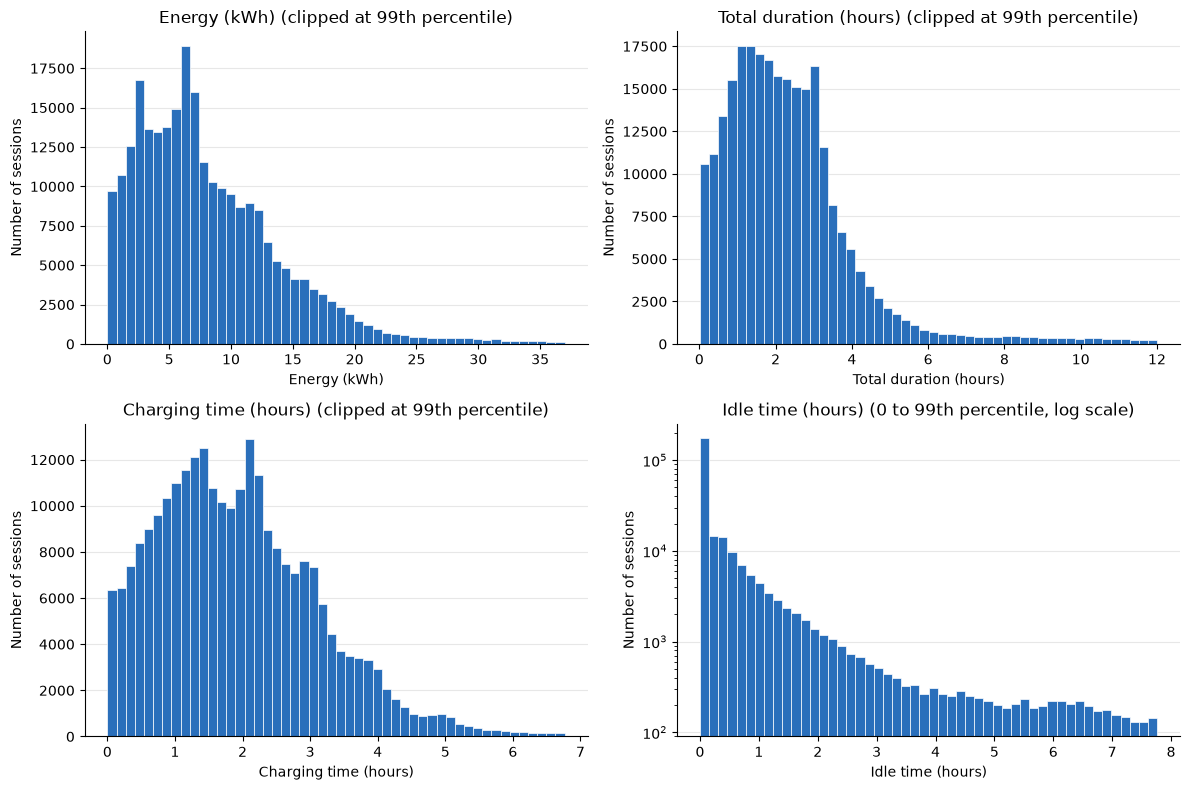

In [15]:
cols = {"energy_kwh": "Energy (kWh)", "total_hours": "Total duration (hours)",
        "charging_hours": "Charging time (hours)", "idle_hours": "Idle time (hours)"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, label) in zip(axes.flat, cols.items()):
    p99 = df[col].quantile(0.99)
    low = 0 if col == "idle_hours" else df[col].min()
    data = df.loc[(df[col] >= low) & (df[col] <= p99), col]
    ax.hist(data, bins=50, color="#2a6fbb", edgecolor="white", linewidth=0.5)
    if col == "idle_hours":
        ax.set_yscale("log")
        ax.set_title(f"{label} (0 to 99th percentile, log scale)")
    else:
        ax.set_title(f"{label} (clipped at 99th percentile)")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of sessions")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Fees of paid sessions and share of free sessions.

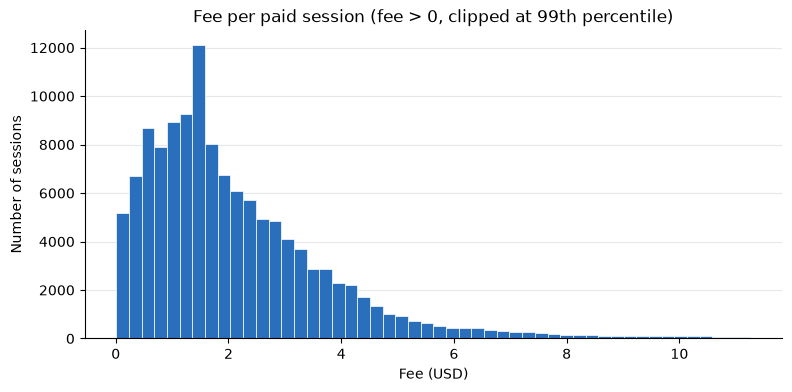

Free sessions (fee == 0): 51.5%
Median fee of paid sessions: 1.69 USD


In [16]:
paid = df.loc[df["fee"] > 0, "fee"]
p99 = paid.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(paid[paid <= p99], bins=50, color="#2a6fbb", edgecolor="white", linewidth=0.5)
ax.set_title("Fee per paid session (fee > 0, clipped at 99th percentile)")
ax.set_xlabel("Fee (USD)")
ax.set_ylabel("Number of sessions")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Free sessions (fee == 0): {(df['fee'] == 0).mean() * 100:.1f}%")
print(f"Median fee of paid sessions: {paid.median():.2f} USD")

Outliers beyond the whiskers are mostly genuine long sessions, so 1.4 uses physical rules instead of the IQR rule.

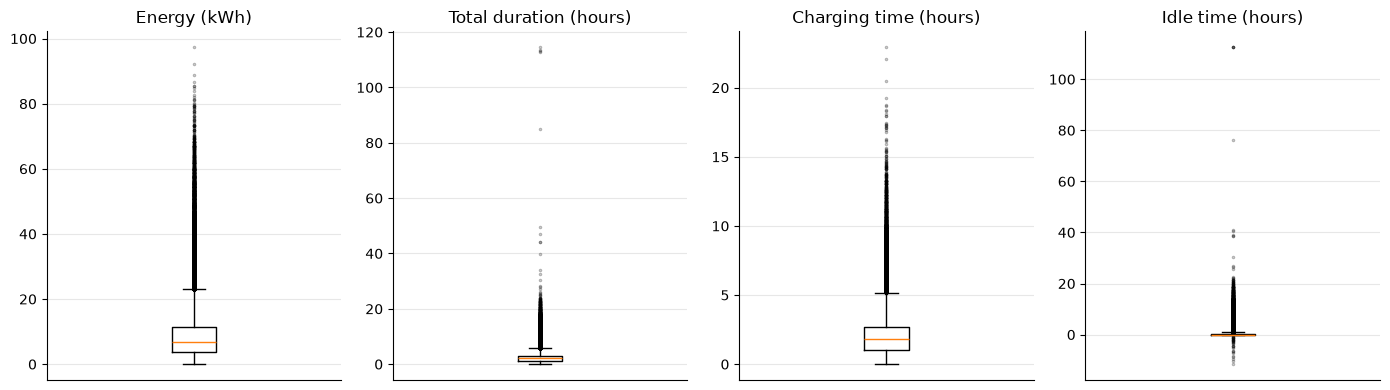

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (col, label) in zip(axes, cols.items()):
    ax.boxplot(df[col].dropna(), flierprops={"marker": ".", "markersize": 3, "alpha": 0.3})
    ax.set_title(label)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The upper edge (≈ 6.6 kWh per hour) is the Level 2 power limit; points far below it are hoarding, points above it are impossible.

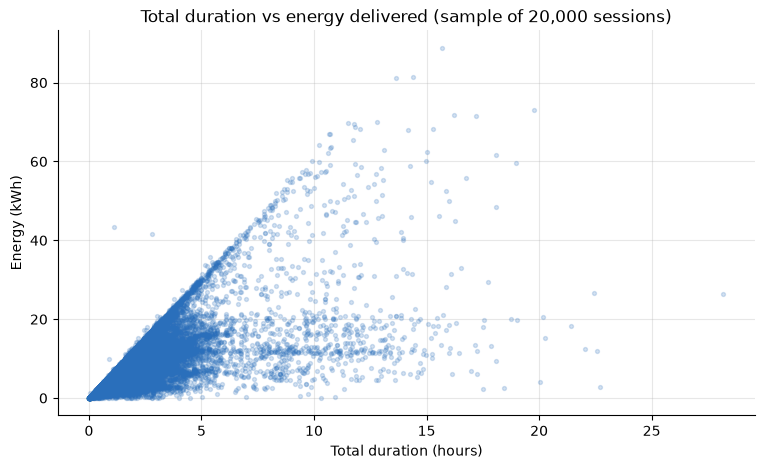

In [18]:
sample = df.sample(20000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample["total_hours"], sample["energy_kwh"], s=8, alpha=0.2, color="#2a6fbb")
ax.set_title("Total duration vs energy delivered (sample of 20,000 sessions)")
ax.set_xlabel("Total duration (hours)")
ax.set_ylabel("Energy (kWh)")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Sessions breaking each candidate rule.

In [19]:
checks = {
    "Total duration < 2 min": df["total_hours"] < 2 / 60,
    "Total duration > 24 h": df["total_hours"] > 24,
    "Charging time > total duration (negative idle)": df["charging_hours"] > df["total_hours"],
    "Avg power > 20 kW (impossible for Level 2)": df["energy_kwh"] / df["charging_hours"].where(df["charging_hours"] > 0) > 20,
    "Energy < 0.1 kWh": df["energy_kwh"] < 0.1,
    "Negative fee": df["fee"] < 0,
    "UTC time zone": (df["start_tz"] == "UTC") | (df["end_tz"] == "UTC"),
    "Currency not USD": df["currency"].notna() & (df["currency"] != "USD"),
    "Currency missing": df["currency"].isna(),
    "User ID missing": df["user_id"].isna(),
    "Duplicated rows": df.duplicated(),
}

suspicious = pd.DataFrame({
    "Sessions": {k: v.sum() for k, v in checks.items()},
    "%": {k: round(v.mean() * 100, 2) for k, v in checks.items()},
})
print(suspicious)

                                                Sessions     %
Total duration < 2 min                              1272  0.49
Total duration > 24 h                                 22  0.01
Charging time > total duration (negative idle)        45  0.02
Avg power > 20 kW (impossible for Level 2)            10  0.00
Energy < 0.1 kWh                                    1831  0.71
Negative fee                                           0  0.00
UTC time zone                                         32  0.01
Currency not USD                                      14  0.01
Currency missing                                    1788  0.69
User ID missing                                     7677  2.96
Duplicated rows                                        4  0.00


**Key findings.** All variables are right-skewed; 12% of sessions idle over 1 h (hoarding). Fees exist only from mid-2017, so free vs paid reflects pricing, not behaviour.

-----------------------------------------

<a id="1.4"></a>
    
## <font color='#FFFFF'>1.4. Treating Inconsistencies <font>

Sessions are corrected or removed with physical rules; `log_step` records how many rows each step removes.

In [20]:
n_initial = len(df)
cleaning_log = []

def log_step(step, n_before):
    cleaning_log.append((step, n_before - len(df), len(df)))
    print(f"{step}: {n_before - len(df)} rows removed, {len(df)} remaining")

**1. Duplicates:** the same session recorded twice.

In [21]:
n_before = len(df)
df = df.drop_duplicates()
log_step("Duplicates", n_before)

Duplicates: 4 rows removed, 259411 remaining


**2. Time zones:** UTC timestamps converted to Pacific time.

In [ ]:
# Only the UTC rows change timezones
utc_start = df["start_tz"] == "UTC"
utc_end = df["end_tz"] == "UTC"

df.loc[utc_start, "start"] = (df.loc[utc_start, "start"]
                              .dt.tz_localize("UTC").dt.tz_convert("America/Los_Angeles").dt.tz_localize(None))
df.loc[utc_end, "end"] = (df.loc[utc_end, "end"]
                          .dt.tz_localize("UTC").dt.tz_convert("America/Los_Angeles").dt.tz_localize(None))

print("Start times converted:", utc_start.sum())
print("End times converted:", utc_end.sum())
df.loc[utc_start, "start_tz"] = "Pacific (converted)"
df.loc[utc_end, "end_tz"] = "Pacific (converted)"
log_step("Time zones (UTC to Pacific)", len(df))

Start times converted: 31
End times converted: 1
Time zones (UTC to Pacific): 0 rows removed, 259411 remaining


**3. Invalid durations:** under 2 minutes, over 24 hours, or charging longer than plugged in.

In [23]:
# Sessions over 24 h are extreme hoarding cases: report them before removing (useful for the exploratory part)
long_sessions = df["total_hours"] > 24
print(f"Sessions over 24 h: {long_sessions.sum()}, mean idle time {df.loc[long_sessions, 'idle_hours'].mean():.1f} h")

# < 2 min: connection failures; > 24 h: unrealistic or faulty; charging > total: physically impossible
n_before = len(df)
invalid_duration = ((df["total_hours"] < 2 / 60) |
                    (df["total_hours"] > 24) |
                    (df["charging_hours"] > df["total_hours"]))
df = df[~invalid_duration]
log_step("Invalid durations", n_before)

Sessions over 24 h: 22, mean idle time 45.3 h
Invalid durations: 1338 rows removed, 258073 remaining


**4. Near-empty sessions:** under 0.1 kWh, no real charging.

In [24]:
n_before = len(df)
df = df[df["energy_kwh"] >= 0.1]
log_step("Near-empty sessions (< 0.1 kWh)", n_before)

Near-empty sessions (< 0.1 kWh): 768 rows removed, 257305 remaining


**5. Impossible power:** above 20 kW (Level 2 delivers ~6.6 kW).

In [ ]:
# Average power = energy / charging time where() avoids dividing by zero
n_before = len(df)
avg_power = df["energy_kwh"] / df["charging_hours"].where(df["charging_hours"] > 0)
df = df[~(avg_power > 20)]
log_step("Implausible power (> 20 kW)", n_before)

Implausible power (> 20 kW): 10 rows removed, 257295 remaining


**6. Port type:** the 9 missing values are filled from the plug type.

In [26]:
plug_to_port = {"J1772": "Level 2", "NEMA 5-20R": "Level 1"}
missing_port = df["port_type"].isna()
df.loc[missing_port, "port_type"] = df.loc[missing_port, "plug_type"].map(plug_to_port)
print("Port types filled:", missing_port.sum(), "| still missing:", df["port_type"].isna().sum())
log_step("Port type filled from plug type", len(df))

Port types filled: 9 | still missing: 0
Port type filled from plug type: 0 rows removed, 257295 remaining


**7. Currency:** non-USD sessions are kept with their fee set to missing, since the energy is real. Missing currency is assumed to be USD.

In [ ]:
non_usd = df["currency"].notna() & (df["currency"] != "USD")
df.loc[non_usd, "fee"] = np.nan
print("Non-USD sessions kept, fee set to NaN:", non_usd.sum())

#CHECK THIS PART
# Missing currency = USD: these sessions are free (before fees were introduced in 2017)

missing_cur = df["currency"].isna()
paid_missing = df.loc[missing_cur & (df["fee"] > 0), "fee"]
print(f"Missing currency: {missing_cur.sum()} sessions, {(df.loc[missing_cur, 'fee'] == 0).sum()} free, "
      f"{len(paid_missing)} paid (median {paid_missing.median():.2f} USD vs {df.loc[df['fee'] > 0, 'fee'].median():.2f} overall)")

df = df.drop(columns="currency")  # now constant
log_step("Non-USD fee set to missing", len(df))

Non-USD sessions kept, fee set to NaN: 13
Missing currency: 1761 sessions, 1689 free, 72 paid (median 1.67 USD vs 1.69 overall)
Non-USD fee set to missing: 0 rows removed, 257295 remaining


**8. Station identity:** stations are keyed by name, not MAC: 33 stations used 68 MACs (hardware swaps), and one MAC moved from HAMILTON #2 to BRYANT #3 in January 2016.

In [28]:
# Safeguard only: no station name has leading/trailing spaces in this dataset
df["station"] = df["station"].astype(str).str.strip().astype("category")

**9. End time:** recomputed as start + total duration, which the charger records reliably.

In [29]:
# Fills the 40 Excel-format end dates and corrects ends off by a day or by daylight-saving shifts
new_end = df["start"] + df["total_duration"]
print("End values missing before:", df["end"].isna().sum())
print("End values changed by > 1 min:", ((new_end - df["end"]).abs() > pd.Timedelta(minutes=1)).sum())
df["end"] = new_end
log_step("End recomputed (start + duration)", len(df))

End values missing before: 40
End values changed by > 1 min: 462
End recomputed (start + duration): 0 rows removed, 257295 remaining


**10. Overlapping sessions:** two cars cannot share a port; a 1-minute tolerance absorbs rounding.

In [ ]:
# Sort by station, port and time shift() gives the end of the previous session on the same port.
# Start times have no seconds, so overlaps under 1 minute are rounding, not real overlaps.
n_before = len(df)
df = df.sort_values(["station", "port_number", "start"])
prev_end = df.groupby(["station", "port_number"], observed=True)["end"].shift()
df = df[~(df["start"] < prev_end - pd.Timedelta(minutes=1))].sort_index()
log_step("Overlapping sessions on the same port", n_before)

Overlapping sessions on the same port: 72 rows removed, 257223 remaining


**11. Study period:** before March 2020, excluding COVID-19 (this also drops SHERMAN and “BRYANT # 1”).

In [31]:
n_before = len(df)
df = df[df["start"] < "2020-03-01"]
df["station"] = df["station"].cat.remove_unused_categories()
print("Stations remaining:", df["station"].nunique())
print("Date range:", df["start"].min(), "to", df["start"].max())
log_step("Study period (before March 2020)", n_before)

Stations remaining: 33
Date range: 2011-07-29 20:17:00 to 2020-02-29 21:47:00
Study period (before March 2020): 11487 rows removed, 245736 remaining


Sessions and active stations per year. Suggestion for forecasting: start in 2016, when the network has 22+ stations; clustering can use the whole period.

In [32]:
yearly = df.groupby(df["start"].dt.year).agg(sessions=("start", "size"),
                                              active_stations=("station", "nunique"))
yearly

,sessions,active_stations
start,,
2011,1265,5
2012,6540,5
2013,9930,5
2014,11553,11
2015,22891,17
2016,46552,22
2017,48668,27
2018,42494,33
2019,47378,33


Active intervals: first to last session, minus gaps over 30 days (likely outages). Hourly series are NaN outside them, not 0. CAMBRIDGE #3's 32-day gap is a clear outage (~36 sessions/week before and after, neighbours busy).

In [33]:
gap_limit = pd.Timedelta(days=30)
records = []
for station, g in df.sort_values("start").groupby("station", observed=True):
    last_end = g["end"].cummax().shift()  # latest plug-out before each session
    is_gap = (g["start"] - last_end) > gap_limit
    gaps = list(zip(last_end[is_gap], g["start"][is_gap]))  # (inactive from, inactive until)
    records.append({"station": station, "start": g["start"].min(), "end": g["end"].max(), "gaps": gaps})

station_active = pd.DataFrame(records).sort_values("start").reset_index(drop=True)
station_active["n_gaps"] = station_active["gaps"].str.len()
print(station_active[["station", "start", "end", "n_gaps"]].to_string(index=False))

gap_table = pd.DataFrame([(row.station, a, b) for row in station_active.itertuples() for a, b in row.gaps],
                         columns=["station", "inactive_from", "inactive_until"])
gap_table["days"] = (gap_table["inactive_until"] - gap_table["inactive_from"]).dt.days
print()
print(gap_table[["station", "inactive_from", "inactive_until", "days"]].to_string(index=False))

                       station               start                 end  n_gaps
    PALO ALTO CA / HAMILTON #1 2011-07-29 20:17:00 2020-02-29 20:59:39       0
    PALO ALTO CA / HAMILTON #2 2011-08-02 12:26:00 2020-02-29 21:26:06       0
        PALO ALTO CA / HIGH #4 2011-09-02 20:42:00 2020-02-29 19:08:25       0
      PALO ALTO CA / BRYANT #2 2011-10-10 15:23:00 2020-02-28 19:56:40       0
      PALO ALTO CA / BRYANT #1 2011-10-13 12:49:00 2020-02-29 20:42:56       0
         PALO ALTO CA / MPL #4 2014-09-24 08:26:00 2020-02-28 21:36:27       2
         PALO ALTO CA / MPL #6 2014-09-24 08:36:00 2020-02-29 22:26:43       1
         PALO ALTO CA / MPL #2 2014-09-24 08:45:00 2020-02-26 21:03:33       2
         PALO ALTO CA / MPL #1 2014-09-27 15:54:00 2020-02-22 18:10:15       4
         PALO ALTO CA / MPL #5 2014-09-28 10:45:00 2020-02-29 17:55:46       2
         PALO ALTO CA / MPL #3 2014-10-05 09:50:00 2020-02-17 16:36:50       3
PALO ALTO CA / RINCONADA LIB 2 2015-01-02 08:43:00 2

Timeline of active stations (white breaks are inactive periods).

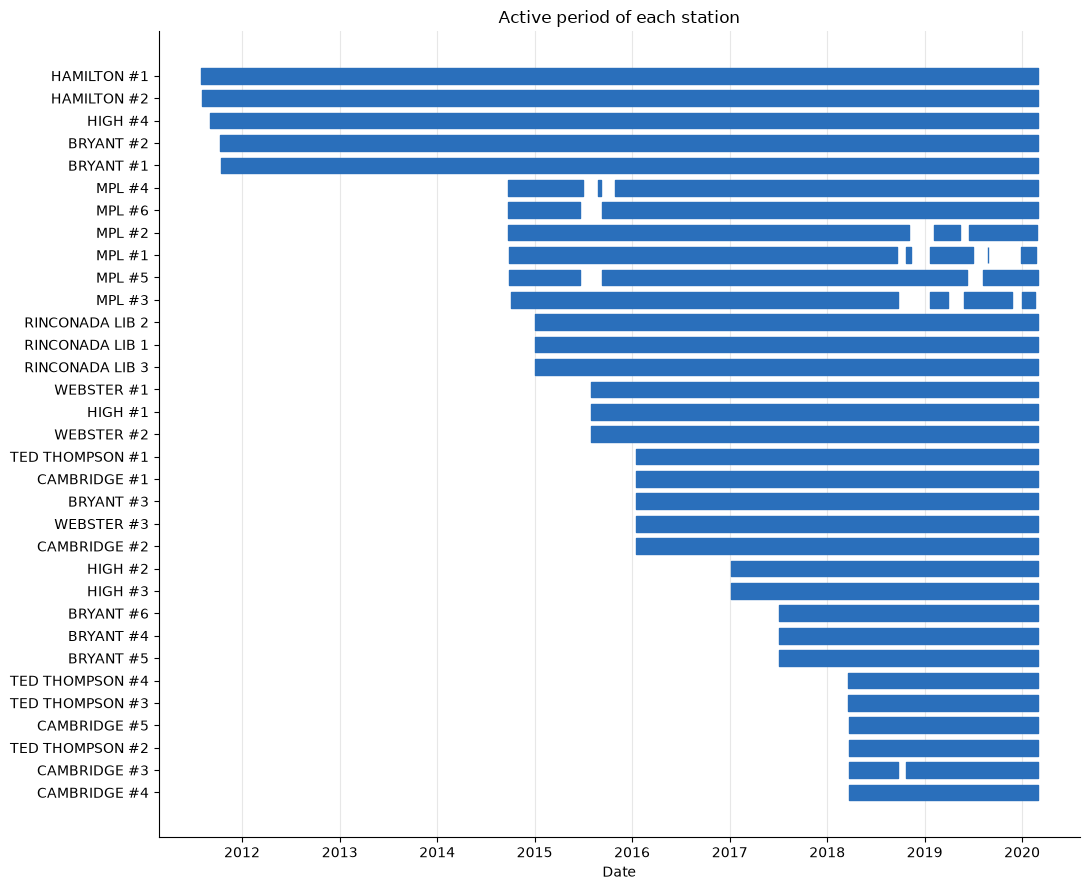

In [34]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(11, 9))
for i, row in station_active.iterrows():
    bounds = [row["start"]] + [t for gap in row["gaps"] for t in gap] + [row["end"]]
    segments = [(mdates.date2num(bounds[k]), mdates.date2num(bounds[k + 1]) - mdates.date2num(bounds[k]))
                for k in range(0, len(bounds), 2)]
    ax.broken_barh(segments, (i - 0.35, 0.7), color="#2a6fbb")
ax.set_yticks(range(len(station_active)))
ax.set_yticklabels(station_active["station"].str.replace("PALO ALTO CA / ", ""))
ax.invert_yaxis()
ax.xaxis_date()
ax.set_title("Active period of each station")
ax.set_xlabel("Date")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Sessions without User ID are kept for forecasting and excluded only in clustering.

In [35]:
print(f"Sessions without user_id: {df['user_id'].isna().sum()} ({df['user_id'].isna().mean() * 100:.2f}%)")

Sessions without user_id: 7153 (2.91%)


Cleaning log.

In [36]:
log_df = pd.DataFrame(cleaning_log, columns=["Step", "Rows removed", "Rows remaining"])
log_df["% of original"] = (log_df["Rows remaining"] / n_initial * 100).round(2)
print(log_df.to_string(index=False))
print("\nFinal shape:", df.shape)

                                 Step  Rows removed  Rows remaining  % of original
                           Duplicates             4          259411         100.00
          Time zones (UTC to Pacific)             0          259411         100.00
                    Invalid durations          1338          258073          99.48
      Near-empty sessions (< 0.1 kWh)           768          257305          99.19
          Implausible power (> 20 kW)            10          257295          99.18
      Port type filled from plug type             0          257295          99.18
           Non-USD fee set to missing             0          257295          99.18
    End recomputed (start + duration)             0          257295          99.18
Overlapping sessions on the same port            72          257223          99.16
     Study period (before March 2020)         11487          245736          94.73

Final shape: (245736, 27)


Cleaned data.

In [37]:
df.head()

,station,mac_address,start,start_tz,end,end_tz,transaction_date,total_duration,charging_time,energy_kwh,ghg_kg,gasoline_gal,port_type,port_number,plug_type,address,postal_code,lat,lon,fee,ended_by,event_id,driver_postal_code,user_id,total_hours,charging_hours,idle_hours
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:32,PDT,2011-07-29 23:20:00,0 days 03:03:32,0 days 01:54:03,6.249457,2.625,0.784,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,3,95124,3284,3.058889,1.900833,1.158056
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:06,PDT,2011-07-30 00:02:00,0 days 00:02:06,0 days 00:01:54,0.106588,0.045,0.013,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Customer,4,94301,4169,0.035000,0.031667,0.003333
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 08:16:00,PDT,2011-07-30 12:33:32,PDT,2011-07-30 12:34:00,0 days 04:17:32,0 days 04:17:28,14.951777,6.280,1.876,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,5,94301,4169,4.292222,4.291111,0.001111
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 14:51:00,PDT,2011-07-30 16:54:24,PDT,2011-07-30 16:55:00,0 days 02:03:24,0 days 02:02:58,7.159643,3.007,0.899,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Customer,6,94302,2545,2.056667,2.049444,0.007222
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,2011-07-30 18:51:00,PDT,2011-07-30 20:02:24,PDT,2011-07-30 20:03:00,0 days 01:11:24,0 days 00:43:54,1.957765,0.822,0.246,Level 2,2,J1772,250 Hamilton Ave,94301,37.444572,-122.160309,0.0,Plug Out at Vehicle,7,94043,3765,1.190000,0.731667,0.458333


**Summary of 1.4**

- 13,679 sessions (5.27%) removed, leaving 245,736 sessions, 27 columns and 33 stations (Jul 2011 – Feb 2020); only 2,192 (0.84%) are data errors, the rest is the pre-COVID period.
- The 22 sessions over 24 h (mean idle 45 h) are extreme hoarding.
- Assumptions: missing currency is USD, non-USD fees are set to missing, UTC times are converted.
- 7 stations (mostly MPL) have 15 outages of over 30 days, stored in `station_active.pkl`.

-----------------------------------------

<a id="1.7"></a>
    
## <font color='#FFFFF'>1.7. Exporting the Datasets <font>

Clean sessions and station activity intervals are saved as pickles (types preserved); load them with `pd.read_pickle`.

In [38]:
df.to_pickle("Data/ev_clean.pkl")
station_active.to_pickle("Data/station_active.pkl")
print("Saved ev_clean.pkl:", df.shape, "| station_active.pkl:", station_active.shape)

Saved ev_clean.pkl: (245736, 27) | station_active.pkl: (33, 5)
